# Model A: standard CNN for EuroSAT

Run the cells from top to bottom using the project's `.venv` Python kernel.
The workflow is **import -> load and view data -> split -> build Model A -> compile -> train -> evaluate**.
The training cell runs 20 epochs; downloading and inspecting data do not start training.

## 1. Import the libraries

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import platform
import sys
import time
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras import layers
from IPython.display import display

print('Python:', sys.executable)
print('TensorFlow:', tf.__version__)
print('Devices:', tf.config.list_physical_devices())

Python: c:\Users\rashmika\Desktop\CNN-For-Image-Classification\.venv\Scripts\python.exe
TensorFlow: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Set paths and training settings

`DATA_DIR` can point to an existing EuroSAT folder. Otherwise the next section downloads
and verifies the official RGB ZIP (about 95 MB). Nested class folders are detected automatically.
The same saved split should be reused for Model B and the pretrained networks.

In [2]:
PROJECT_DIR = Path.cwd().resolve()
DATA_DIR = PROJECT_DIR / 'EuroSAT_RGB'
DATA_ARCHIVE = None  # Optional path to an already downloaded official ZIP.
DOWNLOAD_DATASET = True  # Used only when no extracted dataset is found.
DATASET_URL = 'https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1'
DATASET_MD5 = 'f46e308c4d50d4bf32fedad2d3d62f3b'
SAVED_MANIFEST = None  # Optional path to a previous split_manifest.csv.

SEED = 42
IMAGE_SIZE = (64, 64)  # Height, width. Maximum assignment resolution.
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 0.001
CACHE_IMAGES = True  # Set False if RAM is limited.
RUN_OPTIMIZER_COMPARISON = False  # True runs two additional 20-epoch trials.
CLASS_NAMES = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
               'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

DATA_DIR = Path(DATA_DIR).expanduser().resolve()
RUN_DIR = PROJECT_DIR / 'eurosat_results' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR.mkdir(parents=True, exist_ok=False)
MODEL_SAVE_PATH = RUN_DIR / 'model_a.keras'
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print('Dataset:', DATA_DIR)
print('Results:', RUN_DIR)

Dataset: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\EuroSAT_RGB
Results: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\eurosat_results\20261017_184134_962172


## 3. Load the dataset

Use the ten class folders in the official [EuroSAT RGB dataset](https://zenodo.org/records/7711810).
The download runs once; later runs reuse the extracted images.

In [3]:
def is_eurosat_root(folder):
    return all((folder / name).is_dir() for name in CLASS_NAMES)


def find_eurosat_roots(folder):
    folder = Path(folder)
    if not folder.is_dir():
        return []
    if is_eurosat_root(folder):
        return [folder.resolve()]
    return sorted({p.parent.resolve() for p in folder.rglob('AnnualCrop')
                   if p.is_dir() and is_eurosat_root(p.parent)})


roots = find_eurosat_roots(DATA_DIR)
if not roots and (DOWNLOAD_DATASET or DATA_ARCHIVE is not None):
    if DATA_DIR.exists() and any(DATA_DIR.iterdir()):
        raise FileExistsError('DATA_DIR is not empty and no complete dataset was found. '
                              'Choose an empty extraction folder or the correct existing dataset path.')
    if DATA_ARCHIVE is None:
        (PROJECT_DIR / 'data').mkdir(parents=True, exist_ok=True)
        print('Dataset missing: downloading the official EuroSAT RGB ZIP (about 95 MB).')
        print('Later runs reuse the downloaded archive and extracted images.')
        archive_path = Path(tf.keras.utils.get_file(
            fname='EuroSAT_RGB.zip', origin=DATASET_URL,
            cache_dir=str(PROJECT_DIR / 'data'), cache_subdir='downloads',
            file_hash=DATASET_MD5, hash_algorithm='md5', extract=False))
    else:
        archive_path = Path(DATA_ARCHIVE).expanduser().resolve()
        if not archive_path.is_file():
            raise FileNotFoundError(f'ZIP archive not found: {archive_path}')
        with archive_path.open('rb') as stream:
            digest = hashlib.md5()
            for chunk in iter(lambda: stream.read(1024 * 1024), b''):
                digest.update(chunk)
        if digest.hexdigest() != DATASET_MD5:
            raise ValueError('This ZIP does not match the official EuroSAT_RGB.zip checksum. '
                             'For another trusted copy, extract it yourself and point DATA_DIR to it.')
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    extraction_root = DATA_DIR.resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            target = (extraction_root / member.filename).resolve()
            if not target.is_relative_to(extraction_root):
                raise ValueError(f'Unsafe archive path: {member.filename}')
        archive.extractall(extraction_root)
    print('Imported archive:', archive_path)
    roots = find_eurosat_roots(extraction_root)

if len(roots) != 1:
    raise FileNotFoundError(
        f'Expected one complete EuroSAT RGB dataset under {DATA_DIR}; found {roots}. '
        'Set DATA_DIR to the extracted dataset, set DATA_ARCHIVE to the official ZIP, '
        'or enable DOWNLOAD_DATASET in settings.'
    )
DATA_DIR = roots[0]
print('Using class-folder parent:', DATA_DIR)
print('Class example:', DATA_DIR / CLASS_NAMES[0])

Using class-folder parent: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\EuroSAT_RGB\EuroSAT_RGB
Class example: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\EuroSAT_RGB\EuroSAT_RGB\AnnualCrop


In [4]:
# Inspect image dimensions, readability, and duplicates.
records, bad_images = [], []
for class_name in CLASS_NAMES:
    print('Inspecting:', class_name, flush=True)
    files = sorted(p for p in (DATA_DIR / class_name).rglob('*')
                   if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
    if not files:
        raise ValueError(f'No images found in class {class_name}')
    for path in files:
        try:
            with Image.open(path) as image:
                image.load()
                width, height = image.size
                mode = image.mode
                rgb = image.convert('RGB')
                pixel_hash = hashlib.sha256(
                    f'{width}x{height}:'.encode() + rgb.tobytes()).hexdigest()
        except Exception as exc:
            bad_images.append((str(path), str(exc)))
            continue
        records.append({'relative_path': path.relative_to(DATA_DIR).as_posix(),
                        'class_name': class_name, 'label': CLASS_TO_ID[class_name],
                        'width': width, 'height': height, 'mode': mode,
                        'sha256_pixels': pixel_hash})
if bad_images:
    raise ValueError(f'{len(bad_images)} unreadable images. Examples: {bad_images[:5]}')
frame = pd.DataFrame(records).sort_values('relative_path').reset_index(drop=True)
if len(frame) != 27000:
    raise ValueError(f'Expected the full 27,000-image EuroSAT RGB dataset; found {len(frame)}.')
duplicates = frame[frame.duplicated('sha256_pixels', keep=False)]
if not duplicates.empty:
    display(duplicates.head(20))
    raise ValueError('Exact duplicate images found. Group or resolve them before splitting.')
print(f'Loaded {len(frame):,} images in {NUM_CLASSES} classes.')
display(frame.head())

Inspecting: AnnualCrop
Inspecting: Forest
Inspecting: HerbaceousVegetation
Inspecting: Highway
Inspecting: Industrial
Inspecting: Pasture
Inspecting: PermanentCrop
Inspecting: Residential
Inspecting: River
Inspecting: SeaLake
Loaded 27,000 images in 10 classes.


,relative_path,class_name,label,width,height,mode,sha256_pixels
0,AnnualCrop/AnnualCrop_1.jpg,AnnualCrop,0,64,64,RGB,3f128ded62f9f970990c95c9532b93fdd120754bfc092e...
1,AnnualCrop/AnnualCrop_10.jpg,AnnualCrop,0,64,64,RGB,5e3f93196b4a39774dff91a2c4f7659e0a445372e1abeb...
2,AnnualCrop/AnnualCrop_100.jpg,AnnualCrop,0,64,64,RGB,adf8a9f1fbcab853053c2dd91e54dee998e796c1ec386e...
3,AnnualCrop/AnnualCrop_1000.jpg,AnnualCrop,0,64,64,RGB,18f4fd612d5c65efb130d2c242b56f0c536d2b4dfe1095...
4,AnnualCrop/AnnualCrop_1001.jpg,AnnualCrop,0,64,64,RGB,4ab8a9b8a58b95b2c5dc64a9829faede85afa56fc3fb7d...


## 4. Show sample images and check their original sizes

These are the original images, before preprocessing. Inspect the size table and class counts.

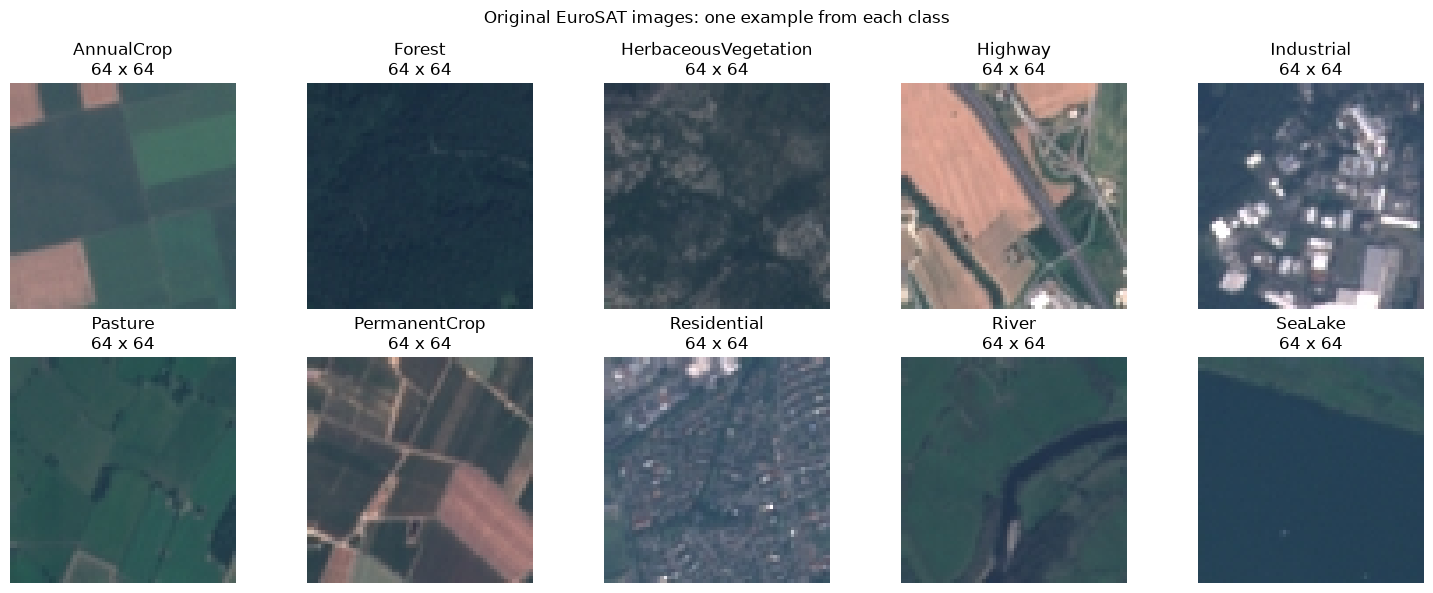

Original image sizes and channels:


,width,height,mode,images
0,64,64,RGB,27000


,images
class_name,
AnnualCrop,3000
Forest,3000
HerbaceousVegetation,3000
Highway,2500
Industrial,2500
Pasture,2000
PermanentCrop,2500
Residential,3000
River,2500


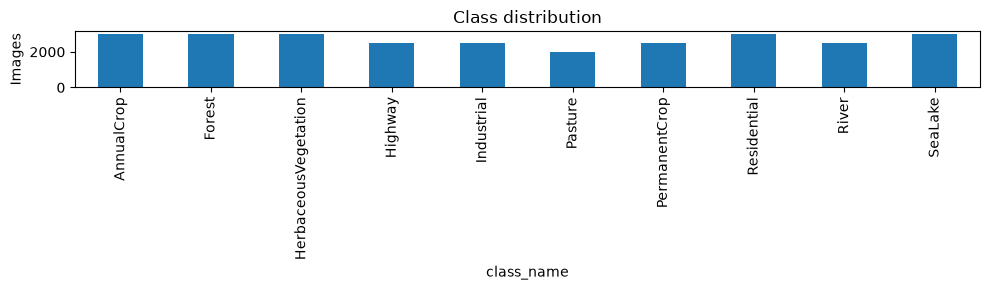

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, name in zip(axes.flat, CLASS_NAMES):
    row = frame[frame['class_name'] == name].sample(1, random_state=SEED).iloc[0]
    with Image.open(DATA_DIR / row['relative_path']) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(f"{name}\n{row['width']} x {row['height']}")
    ax.axis('off')
fig.suptitle('Original EuroSAT images: one example from each class')
fig.tight_layout()
fig.savefig(RUN_DIR / 'class_examples.png', dpi=150)
plt.show()

print('Original image sizes and channels:')
display(frame.groupby(['width', 'height', 'mode']).size().rename('images').reset_index())
counts = frame.groupby('class_name').size().reindex(CLASS_NAMES)
display(counts.rename('images').to_frame())
counts.plot.bar(figsize=(10, 3), ylabel='Images', title='Class distribution')
plt.tight_layout()
plt.savefig(RUN_DIR / 'class_counts.png', dpi=150)
plt.show()

## 5. Split 70% / 15% / 15% and prepare batches

Stratify by class using seed 42: 18,900 training, 4,050 validation, and 4,050 test images.
Save the manifest for reuse by every model. Shuffle training data only.
The test split stays separate while choosing the model and optimizer.

In [6]:
if SAVED_MANIFEST is None:
    train_part, held_out = train_test_split(frame, test_size=0.30,
                                          stratify=frame['label'], random_state=SEED)
    val_part, test_part = train_test_split(held_out, test_size=0.50,
                                         stratify=held_out['label'], random_state=SEED)
    frame['split'] = ''
    for name, part in [('train', train_part), ('val', val_part), ('test', test_part)]:
        frame.loc[part.index, 'split'] = name
else:
    saved = pd.read_csv(SAVED_MANIFEST)
    columns = ['relative_path', 'class_name', 'label', 'sha256_pixels']
    current = frame[columns].sort_values('relative_path').reset_index(drop=True)
    expected = saved[columns].sort_values('relative_path').reset_index(drop=True)
    pd.testing.assert_frame_equal(current, expected, check_dtype=False)
    frame = frame.merge(saved[['relative_path', 'split']], on='relative_path', validate='one_to_one')
assert frame['relative_path'].is_unique
assert frame['split'].value_counts().to_dict() == {'train': 18900, 'val': 4050, 'test': 4050}
assert frame.groupby('sha256_pixels')['split'].nunique().max() == 1
manifest_text = frame.sort_values('relative_path').to_csv(index=False, lineterminator='\n')
(RUN_DIR / 'split_manifest.csv').write_bytes(manifest_text.encode('utf-8'))
MANIFEST_HASH = hashlib.sha256(manifest_text.encode()).hexdigest()
(RUN_DIR / 'split_manifest.sha256').write_text(MANIFEST_HASH, encoding='utf-8')
(RUN_DIR / 'class_names.json').write_text(json.dumps(CLASS_NAMES, indent=2), encoding='utf-8')
display(pd.crosstab(frame['class_name'], frame['split']).reindex(CLASS_NAMES))
print('Manifest hash:', MANIFEST_HASH)
train_frame = frame[frame['split'] == 'train'].copy()
val_frame = frame[frame['split'] == 'val'].copy()
test_frame = frame[frame['split'] == 'test'].copy()

split,test,train,val
class_name,,,
AnnualCrop,450,2100,450
Forest,450,2100,450
HerbaceousVegetation,450,2100,450
Highway,375,1750,375
Industrial,375,1750,375
Pasture,300,1400,300
PermanentCrop,375,1750,375
Residential,450,2100,450
River,375,1750,375


Manifest hash: 5bd934c2a773cd37de70ac60d2e0119837d839bbbe4d6d865d6f0820b20231e0


In [7]:
def decode_for_model(path, label):
    # EuroSAT RGB images are already 64 x 64. Keep raw uint8 pixels;
    # the model's Rescaling layer converts [0, 255] to [0, 1].
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.ensure_shape(image, (64, 64, 3)), label


def make_dataset(part, training=False):
    paths = [str(DATA_DIR / relative) for relative in part['relative_path']]
    labels = part['label'].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(decode_for_model, num_parallel_calls=tf.data.AUTOTUNE)
    if CACHE_IMAGES:
        dataset = dataset.cache()  # Cache uint8 images to reduce memory use.
    if training:
        dataset = dataset.shuffle(len(part), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE, drop_remainder=False)
    expected_batches = (len(part) + BATCH_SIZE - 1) // BATCH_SIZE
    dataset = dataset.apply(tf.data.experimental.assert_cardinality(expected_batches))
    options = tf.data.Options()
    options.experimental_deterministic = True
    return dataset.with_options(options).prefetch(tf.data.AUTOTUNE)

preview_ds = make_dataset(train_frame.head(BATCH_SIZE))
images, labels = next(iter(preview_ds))
print('Batch shape:', images.shape, '| dtype:', images.dtype)
print('Pixel range:', int(tf.reduce_min(images)), 'to', int(tf.reduce_max(images)))
print('Labels:', labels[:10].numpy())
del preview_ds

Batch shape: (32, 64, 64, 3) | dtype: <dtype: 'uint8'>
Pixel range: 24 to 255
Labels: [0 0 0 0 0 0 0 0 0 0]


## 6. Create Model A: standard CNN

Four Conv2D + ReLU + max-pooling blocks use 32, 64, 128, and 256 filters with 3 x 3 kernels.
Pooling reduces spatial sizes from 64 to 32, 16, 8, and 4.
Flatten converts the final 4 x 4 x 256 feature maps into 4,096 features.
A Dense layer produces one score per class (ten for EuroSAT), followed by Softmax
which converts these scores into class probabilities that sum to one.

**Architecture: (Conv2D + ReLU -> MaxPooling) x 4 -> Flatten -> Dense(NUM_CLASSES) -> Softmax.**

The expected trainable parameter count is **429,386** for ten classes.
The sub-100k limit applies to Model B.


In [8]:
def build_model_a():
    inputs = layers.Input(shape=(64, 64, 3), name='rgb_0_255')
    x = layers.Rescaling(1.0 / 255, name='rescale')(inputs)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding='same', activation='relu',
                          name=f'conv_{filters}')(x)
        x = layers.MaxPooling2D(2, name=f'pool_{filters}')(x)
    x = layers.Flatten(name='flatten')(x)
    logits = layers.Dense(NUM_CLASSES, name='class_scores')(x)
    outputs = layers.Softmax(name='class_probabilities')(logits)
    return tf.keras.Model(inputs, outputs, name='Model_A_EuroSAT')

model_a = build_model_a()
model_a.summary()
assert model_a.count_params() == 388416 + (4096 + 1) * NUM_CLASSES
initial_weights = model_a.get_weights()

Model: "Model_A_EuroSAT"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_0_255 (InputLayer)          │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_32 (Conv2D)                │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_32 (MaxPooling2D)          │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_64 (Conv2D)                │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_64 (MaxPooling2D)          │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_128 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_128 (MaxPooling2D)         │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_256 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_256 (MaxPooling2D)         │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_scores (Dense)            │ (None, 10)             │        40,970 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Softmax)   │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 429,386 (1.64 MB)

 Trainable params: 429,386 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

### Calculate parameters and computation

Conv parameters = kernel height x kernel width x input channels x output channels + biases.
Dense parameters = inputs x units + biases. One MAC is one multiplication with accumulation.
The MAC estimate below counts Conv/Dense only, excluding pooling, activations, and scaling.

In [9]:
rows, size, channels = [], 64, 3
for filters in [32, 64, 128, 256]:
    rows.append({'layer': f'Conv2D {filters}',
                 'parameters': 9 * channels * filters + filters,
                 'MACs': size * size * 9 * channels * filters})
    channels, size = filters, size // 2
flattened_features = size * size * channels
rows.append({'layer': f'Dense {NUM_CLASSES}',
             'parameters': flattened_features * NUM_CLASSES + NUM_CLASSES,
             'MACs': flattened_features * NUM_CLASSES})
cost_table = pd.DataFrame(rows)
display(cost_table)
TOTAL_PARAMS = int(cost_table['parameters'].sum())
TOTAL_MACS = int(cost_table['MACs'].sum())
assert TOTAL_PARAMS == model_a.count_params()
print('Total parameters:', TOTAL_PARAMS)
print('Conv/Dense MACs per image:', TOTAL_MACS)
cost_table.to_csv(RUN_DIR / 'model_a_cost.csv', index=False)

,layer,parameters,MACs
0,Conv2D 32,896,3538944
1,Conv2D 64,18496,18874368
2,Conv2D 128,73856,18874368
3,Conv2D 256,295168,18874368
4,Dense 10,40970,40960


Total parameters: 429386
Conv/Dense MACs per image: 60203008


## 7. Choose the optimizer and compile

Start with Adam at learning rate 0.001. Integer labels use sparse categorical cross entropy.
Later compare against SGD and SGD with momentum 0.9 using the same split, initial weights,
and 20-epoch budget. The two SGD trials both use learning rate 0.01 to isolate momentum.

In [10]:
model_a.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print('Optimizer: Adam | learning rate:', LEARNING_RATE)
print('Loss: sparse_categorical_crossentropy')

Optimizer: Adam | learning rate: 0.001
Loss: sparse_categorical_crossentropy


## 8. Train Model A for 20 epochs

Run the next two cells when ready to train. CPU training takes longer than inspection.
All epochs run; the checkpoint with lowest validation loss is retained. The test set is not used.
Record the hardware when reporting time per epoch.

In [11]:
class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.seconds = []
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.seconds.append(time.perf_counter() - self.start)


def train_one_trial(name, optimizer_factory, model=None):
    if EPOCHS < 20:
        raise ValueError('Use at least 20 epochs for assignment training runs.')
    tf.keras.utils.set_random_seed(SEED)
    if model is None:
        model = build_model_a()
    model.set_weights(initial_weights)
    model.compile(optimizer=optimizer_factory(),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    trial_dir = RUN_DIR / name
    trial_dir.mkdir(exist_ok=False)
    checkpoint = trial_dir / 'best_full.keras'
    timer = EpochTimer()
    history = model.fit(make_dataset(train_frame, training=True),
                        validation_data=make_dataset(val_frame), epochs=EPOCHS, verbose=2,
                        callbacks=[timer,
                                   tf.keras.callbacks.ModelCheckpoint(str(checkpoint),
                                       monitor='val_loss', mode='min', save_best_only=True),
                                   tf.keras.callbacks.CSVLogger(str(trial_dir / 'epochs.csv'))])
    metrics = {key: [float(v) for v in values] for key, values in history.history.items()}
    if len(metrics['loss']) != EPOCHS or not all(np.isfinite(v).all() for v in metrics.values()):
        raise RuntimeError('Incomplete or non-finite history; investigate before reporting.')
    best = int(np.argmin(metrics['val_loss']))
    result = {'experiment': name, 'best_epoch': best + 1,
              'validation_loss': metrics['val_loss'][best],
              'validation_accuracy': metrics['val_accuracy'][best],
              'mean_epoch_seconds_after_first': float(np.mean(timer.seconds[1:])),
              'checkpoint': str(checkpoint)}
    (trial_dir / 'history.json').write_text(json.dumps(
        {'metrics': metrics, 'epoch_seconds': timer.seconds}, indent=2), encoding='utf-8')
    return metrics, result

In [12]:
BASELINE_NAME = f'adam_lr_{LEARNING_RATE:g}'
history_a, baseline_result = train_one_trial(
    BASELINE_NAME, lambda: tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), model=model_a)
histories = {BASELINE_NAME: history_a}
validation_rows = [baseline_result]
print('Best validation epoch:', baseline_result['best_epoch'])
print('Checkpoint:', baseline_result['checkpoint'])

Epoch 1/20


c:\Users\rashmika\Desktop\CNN-For-Image-Classification\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


591/591 - 41s - 69ms/step - accuracy: 0.5388 - loss: 1.1963 - val_accuracy: 0.6553 - val_loss: 0.9652
Epoch 2/20
591/591 - 34s - 57ms/step - accuracy: 0.7370 - loss: 0.7255 - val_accuracy: 0.7635 - val_loss: 0.6695
Epoch 3/20
591/591 - 35s - 58ms/step - accuracy: 0.7943 - loss: 0.5759 - val_accuracy: 0.7756 - val_loss: 0.6398
Epoch 4/20
591/591 - 35s - 59ms/step - accuracy: 0.8311 - loss: 0.4759 - val_accuracy: 0.8237 - val_loss: 0.5041
Epoch 5/20
591/591 - 36s - 60ms/step - accuracy: 0.8556 - loss: 0.4064 - val_accuracy: 0.8642 - val_loss: 0.3896
Epoch 6/20
591/591 - 36s - 61ms/step - accuracy: 0.8823 - loss: 0.3368 - val_accuracy: 0.8546 - val_loss: 0.4012
Epoch 7/20
591/591 - 37s - 62ms/step - accuracy: 0.8954 - loss: 0.2918 - val_accuracy: 0.8509 - val_loss: 0.4343
Epoch 8/20
591/591 - 36s - 60ms/step - accuracy: 0.9144 - loss: 0.2469 - val_accuracy: 0.8800 - val_loss: 0.3441
Epoch 9/20
591/591 - 47s - 79ms/step - accuracy: 0.9265 - loss: 0.2113 - val_accuracy: 0.8575 - val_loss: 0

## 9. Plot training and validation curves

Compare both loss and accuracy. Falling training loss with rising validation loss suggests
overfitting. Use validation results for tuning; do not choose settings from test accuracy.

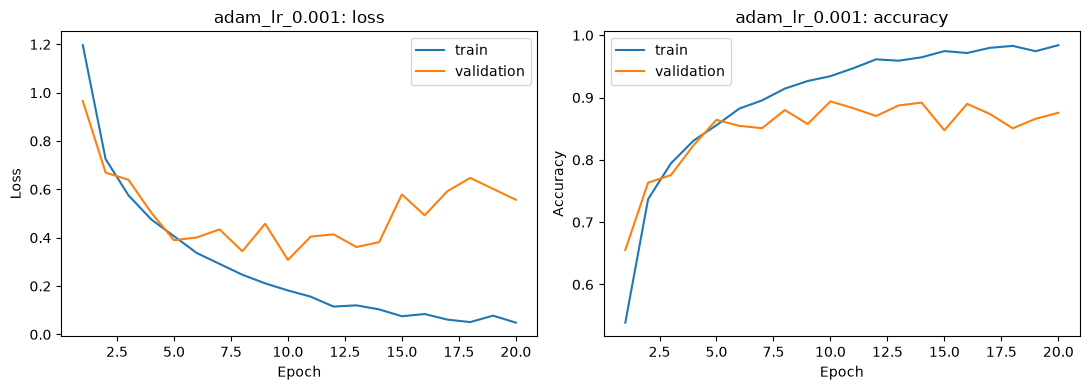

In [13]:
def plot_history(name, history):
    epochs_axis = np.arange(1, len(history['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        ax.plot(epochs_axis, history[metric], label='train')
        ax.plot(epochs_axis, history[f'val_{metric}'], label='validation')
        ax.set(xlabel='Epoch', ylabel=metric.title(), title=f'{name}: {metric}')
        ax.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / name / 'curves.png', dpi=150)
    plt.show()

plot_history(BASELINE_NAME, history_a)

## 10. Optional optimizer comparison and validation selection

Set `RUN_OPTIMIZER_COMPARISON = True` in a new cell before running this section to run SGD
and momentum SGD. Each additional trial starts from the same initial weights and runs 20 epochs.
Momentum 0.9 carries information from previous updates, which can smooth oscillations and
accelerate consistent directions, but may overshoot. Judge its effect from your actual curves.
A single seed and limited learning-rate search are limitations of this comparison.

In [14]:
if RUN_OPTIMIZER_COMPARISON:
    optimizer_trials = [
        ('sgd_lr_0.01', lambda: tf.keras.optimizers.SGD(learning_rate=0.01)),
        ('momentum_0.9_lr_0.01', lambda: tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)),
    ]
    for name, optimizer_factory in optimizer_trials:
        history, result = train_one_trial(name, optimizer_factory)
        histories[name] = history
        validation_rows.append(result)
        plot_history(name, history)
else:
    print('Extra optimizer trials skipped. Set RUN_OPTIMIZER_COMPARISON = True to compare them.')

validation_table = pd.DataFrame(validation_rows)
validation_table.to_csv(RUN_DIR / 'optimizer_validation_comparison.csv', index=False)
display(validation_table.drop(columns='checkpoint'))
selected = min(validation_rows, key=lambda row: row['validation_loss'])
(RUN_DIR / 'selected_model_a.json').write_text(json.dumps(selected, indent=2), encoding='utf-8')
print('Selected by lowest validation loss:', selected['experiment'])

Extra optimizer trials skipped. Set RUN_OPTIMIZER_COMPARISON = True to compare them.


,experiment,best_epoch,validation_loss,validation_accuracy,mean_epoch_seconds_after_first
0,adam_lr_0.001,10,0.308282,0.893827,43.895926


Selected by lowest validation loss: adam_lr_0.001


## 11. Save the selected Model A

Export the best validation checkpoint as `model_a.keras` without optimizer state.
Save the class mapping and input contract alongside it. A validation batch checks that
saving and reloading preserve predictions. This step does not require test evaluation.

In [15]:
if selected is None:
    print('Model export skipped: complete training and validation selection first.')
    print('Planned export path:', MODEL_SAVE_PATH)
else:
    selected_model = tf.keras.models.load_model(selected['checkpoint'], compile=False)
    inference_model = tf.keras.models.clone_model(selected_model)
    inference_model.set_weights(selected_model.get_weights())
    inference_model.save(MODEL_SAVE_PATH)
    reloaded = tf.keras.models.load_model(MODEL_SAVE_PATH, compile=False)
    validation_sample = next(iter(make_dataset(val_frame)))[0][:4]
    np.testing.assert_allclose(selected_model(validation_sample, training=False).numpy(),
                               reloaded(validation_sample, training=False).numpy(), rtol=1e-5, atol=1e-5)
    metadata = {
        'class_names': CLASS_NAMES,
        'input_contract': {'shape': [64, 64, 3], 'pixel_range': [0, 255],
                           'scaling_in_model': True, 'output': 'class probabilities'},
        'split_manifest_sha256': MANIFEST_HASH,
        'selected_experiment': selected,
        'total_parameters': selected_model.count_params(),
        'model_size_KB': MODEL_SAVE_PATH.stat().st_size / 1000,
        'tensorflow': tf.__version__,
    }
    metadata_path = MODEL_SAVE_PATH.with_name(MODEL_SAVE_PATH.stem + '_metadata.json')
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    print('Saved inference model:', MODEL_SAVE_PATH)
    print('Saved model metadata:', metadata_path)
    print('Full training checkpoint:', selected['checkpoint'])

Saved inference model: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\eurosat_results\20261017_184134_962172\model_a.keras
Saved model metadata: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\eurosat_results\20261017_184134_962172\model_a_metadata.json
Full training checkpoint: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\eurosat_results\20261017_184134_962172\adam_lr_0.001\best_full.keras


## 12. Deployment size and final Model A summary

Save the selected checkpoint with optimizer state as `model_a_full.keras` for resuming training.
Save an uncompiled copy as `model_a.keras` for inference. The `.keras` file contains architecture
and metadata as well as weights. Size is reported in **KiB (1,024 bytes)** to match division by 1024.

The float32 and int8 figures below are theoretical raw-weight sizes. The int8 figure is only
an estimate: no quantization is performed. Epoch timing comes from the selected optimizer trial,
excludes the first epoch, includes validation, and excludes checkpoint/CSV writes.

The final section below displays test accuracy, per-class scores, and the confusion matrix.

In [16]:
def deploy_size_kb(model, build_fn, path):
    """Save an uncompiled .keras copy without optimizer state; return size in KiB."""
    clean = build_fn()
    clean.set_weights(model.get_weights())
    path = Path(path)
    clean.save(path)
    return path.stat().st_size / 1024

In [17]:
if not globals().get('selected'):
    print('Complete training and validation selection before saving the Model A summary.')
else:
    # Use the selected best-validation checkpoint, which includes optimizer state.
    # model_a may contain the final epoch rather than the selected best epoch.
    resume_model = tf.keras.models.load_model(selected['checkpoint'])
    full_model_path = RUN_DIR / 'model_a_full.keras'
    resume_model.save(full_model_path)
    size_a_kb = deploy_size_kb(resume_model, build_model_a, MODEL_SAVE_PATH)

    metadata_path = MODEL_SAVE_PATH.with_name(MODEL_SAVE_PATH.stem + '_metadata.json')
    metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    metadata['model_size_KB'] = MODEL_SAVE_PATH.stat().st_size / 1000
    metadata['model_size_KiB'] = size_a_kb
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')

    params_a = resume_model.count_params()
    mean_epoch_seconds_a = selected['mean_epoch_seconds_after_first']
    print(f'Model A: {params_a:,} parameters')
    print(f"  selected optimizer      : {selected['experiment']}")
    print(f'  inference file on disk  : {size_a_kb:.1f} KiB (no optimizer state)')
    print(f'  theoretical float32    : {params_a * 4 / 1024:.1f} KiB (raw weights)')
    print(f'  hypothetical int8      : {params_a / 1024:.1f} KiB (raw weights only; not quantized)')
    print(f'  time per epoch         : {mean_epoch_seconds_a:.2f} s (excludes first epoch)')
    print('  timing includes validation; excludes checkpoint/CSV writes.')
    print('Full model for resuming:', full_model_path)
    print('Inference model:', MODEL_SAVE_PATH)

Model A: 429,386 parameters
  selected optimizer      : adam_lr_0.001
  inference file on disk  : 1722.5 KiB (no optimizer state)
  theoretical float32    : 1677.3 KiB (raw weights)
  hypothetical int8      : 419.3 KiB (raw weights only; not quantized)
  time per epoch         : 43.90 s (excludes first epoch)
  timing includes validation; excludes checkpoint/CSV writes.
Full model for resuming: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\eurosat_results\20261017_184134_962172\model_a_full.keras
Inference model: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\eurosat_results\20261017_184134_962172\model_a.keras


## 13. Final test scores and confusion matrix

Run these final cells after training, validation selection, and model export.
They evaluate the selected model on the held-out test split and display:

- Test accuracy.
- Precision, recall, F1-score, and support for all ten EuroSAT classes.
- Macro and weighted averages.
- A blue confusion matrix with counts, true labels on rows, and predictions on columns.

The report and confusion matrix are also saved in `RUN_DIR`.
Labels and predictions are collected together in one pass to keep their order aligned.


In [18]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay


def evaluate(model, ds, title):
    """Evaluate one pass of paired images/labels; save the report and confusion matrix."""
    true_batches, predicted_batches = [], []
    for images, labels in ds:
        probabilities = model(images, training=False).numpy()
        true_batches.append(labels.numpy())
        predicted_batches.append(np.argmax(probabilities, axis=1))
    if not true_batches:
        raise ValueError('The evaluation dataset is empty.')
    y_true = np.concatenate(true_batches)
    y_pred = np.concatenate(predicted_batches)
    names = CLASS_NAMES
    label_ids = list(range(len(names)))
    acc = float(np.mean(y_true == y_pred))
    print(f'{title} test accuracy: {acc:.4f}\n')
    print(classification_report(y_true, y_pred, labels=label_ids,
                                target_names=names, digits=4, zero_division=0))
    report = classification_report(y_true, y_pred, labels=label_ids,
                                   target_names=names, output_dict=True, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=label_ids)
    fig, ax = plt.subplots(figsize=(10, 9))
    ConfusionMatrixDisplay(cm, display_labels=names).plot(
        ax=ax, cmap='Blues', values_format='d', xticks_rotation=90, colorbar=True)
    ax.set_title(f'{title} - confusion matrix')
    fig.tight_layout()
    stem = title.replace(' ', '_').lower()
    fig.savefig(RUN_DIR / f'{stem}_confusion.png', dpi=150, bbox_inches='tight')
    plt.show()
    np.savetxt(RUN_DIR / f'{stem}_confusion.csv', cm, delimiter=',', fmt='%d')
    (RUN_DIR / f'{stem}_classification_report.json').write_text(
        json.dumps(report, indent=2), encoding='utf-8')
    return acc

Model A test accuracy: 0.9057

                      precision    recall  f1-score   support

          AnnualCrop     0.8710    0.9156    0.8927       450
              Forest     0.9794    0.9489    0.9639       450
HerbaceousVegetation     0.8929    0.8156    0.8525       450
             Highway     0.8583    0.8400    0.8491       375
          Industrial     0.9184    0.9600    0.9387       375
             Pasture     0.8589    0.9533    0.9036       300
       PermanentCrop     0.8426    0.7707    0.8050       375
         Residential     0.9683    0.9511    0.9596       450
               River     0.8424    0.9120    0.8758       375
             SeaLake     0.9888    0.9822    0.9855       450

            accuracy                         0.9057      4050
           macro avg     0.9021    0.9049    0.9026      4050
        weighted avg     0.9064    0.9057    0.9052      4050



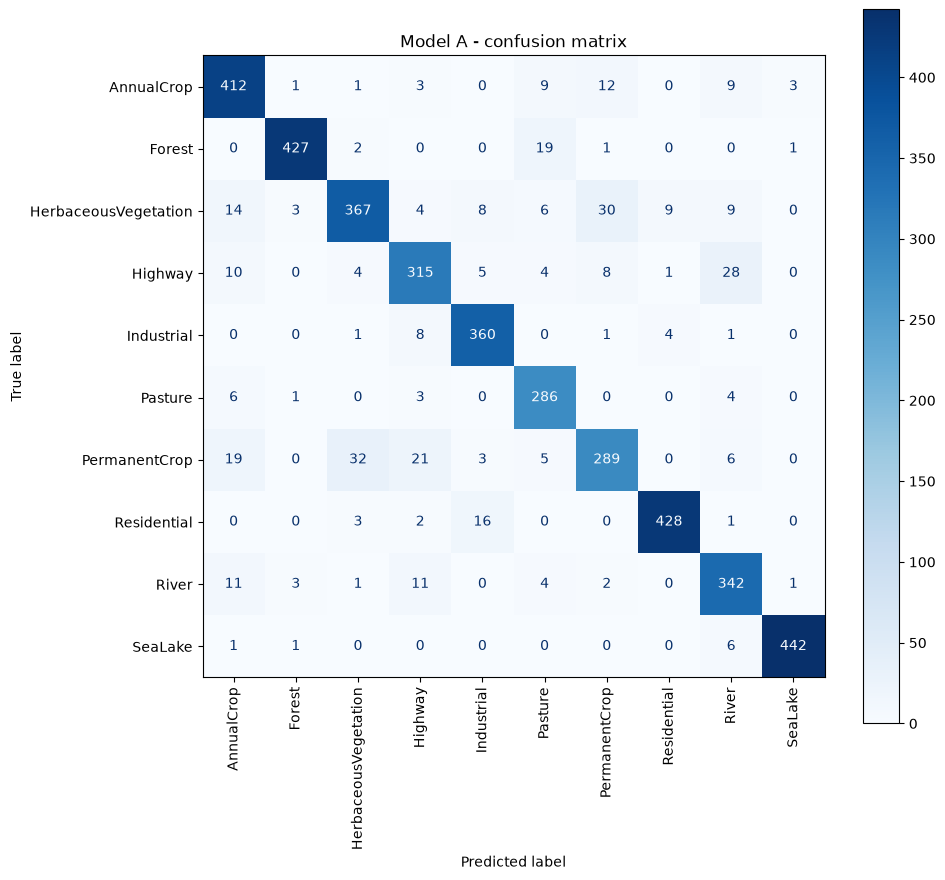

Saved test metrics: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\eurosat_results\20261017_184134_962172\model_a_results.json


In [19]:
if not globals().get('selected'):
    raise ValueError('Complete training and validation selection before final testing.')
if not MODEL_SAVE_PATH.is_file():
    raise FileNotFoundError('Run the export cell before final evaluation.')
best_model = tf.keras.models.load_model(MODEL_SAVE_PATH, compile=False)
test_ds = make_dataset(test_frame)  # Raw RGB pixels; scaling is inside the model.
test_acc_a = evaluate(best_model, test_ds, 'Model A')
report = json.loads((RUN_DIR / 'model_a_classification_report.json').read_text(encoding='utf-8'))
export_path = MODEL_SAVE_PATH
result = {'model': 'Model A', 'selected_experiment': selected,
          'test_accuracy': test_acc_a,
          'macro_precision': report['macro avg']['precision'],
          'macro_recall': report['macro avg']['recall'],
          'macro_f1': report['macro avg']['f1-score'],
          'total_parameters': best_model.count_params(),
          'trainable_parameters': int(sum(np.prod(v.shape) for v in best_model.trainable_weights)),
          'model_size_KB': export_path.stat().st_size / 1000,
          'theoretical_float32_weights_KB': best_model.count_params() * 4 / 1000,
          'estimated_conv_dense_MACs': TOTAL_MACS,
          'class_names': CLASS_NAMES, 'split_manifest_sha256': MANIFEST_HASH,
          'seed': SEED, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
          'input_contract': 'RGB [0,255], shape (N,64,64,3); output class probabilities',
          'environment': {'tensorflow': tf.__version__, 'python': platform.python_version(),
                          'platform': platform.platform(),
                          'devices': [str(device) for device in tf.config.list_physical_devices()]}}
(RUN_DIR / 'model_a_results.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
print('Saved test metrics:', RUN_DIR / 'model_a_results.json')
